# TrustXRay — 02. Baseline model (transfer learning)

**Goal:** train a first deep learning model that classifies chest X-rays as *normal* or *pneumonia*, while handling the problems found in notebook 01:

| Problem found in 01 | How we handle it here |
|---|---|
| Class imbalance (~2.9 pneumonia : 1 normal) | Class-weighted loss (`pos_weight`) |
| Distribution shift train (74%) vs test (62.5%) | Decision threshold chosen on **validation only** |
| Accuracy is misleading (baseline = 62.5%) | Evaluation with **sensitivity, specificity, AUC** and the confusion matrix |

> ⚠️ In Colab: **Runtime → Change runtime type → T4 GPU** before running.

In [1]:
!pip install -q medmnist

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 115.9/115.9 kB 6.4 MB/s eta 0:00:00


In [2]:
import os, time, copy
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from torchvision import transforms, models
from medmnist import PneumoniaMNIST
from sklearn.metrics import roc_auc_score, roc_curve, confusion_matrix

SEED = 42
torch.manual_seed(SEED); np.random.seed(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)
if DEVICE.type == "cpu":
    print("⚠️ No GPU detected: Runtime → Change runtime type → T4 GPU")

SIZE = 224
DATA_DIR = "./data"
FIG_DIR = "./figures"
os.makedirs(DATA_DIR, exist_ok=True); os.makedirs(FIG_DIR, exist_ok=True)

Device: cuda


## 1. Save the model to Google Drive

Colab deletes everything when the session ends. We save the trained model in Google Drive so we can reuse it in the next notebooks (uncertainty, Grad-CAM, Streamlit app).

In [3]:
try:
    from google.colab import drive
    drive.mount("/content/drive")
    SAVE_DIR = "/content/drive/MyDrive/TrustXRay"
except ImportError:
    SAVE_DIR = "./models"
os.makedirs(SAVE_DIR, exist_ok=True)
MODEL_PATH = os.path.join(SAVE_DIR, "resnet18_baseline.pt")
print("Model will be saved to:", MODEL_PATH)

Mounted at /content/drive
Model will be saved to: /content/drive/MyDrive/TrustXRay/resnet18_baseline.pt


## 2. Pre-processing and data augmentation

- The network was pre-trained on ImageNet (color photos) → we convert the grayscale X-ray to 3 channels and use ImageNet normalization.
- **Augmentation** (training only): small rotations, shifts, zoom and contrast changes, to simulate patient positioning and different X-ray machines.
- ⚠️ **No horizontal flip:** the human body is not symmetric (the heart is on the left). Flipping would create anatomically impossible images.

In [4]:
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

train_tf = transforms.Compose([
    transforms.RandomAffine(degrees=10, translate=(0.05, 0.05), scale=(0.95, 1.05)),
    transforms.ColorJitter(brightness=0.1, contrast=0.1),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])
eval_tf = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

train_ds = PneumoniaMNIST(split="train", transform=train_tf, download=True, size=SIZE, as_rgb=True, root=DATA_DIR)
val_ds   = PneumoniaMNIST(split="val",   transform=eval_tf,  download=True, size=SIZE, as_rgb=True, root=DATA_DIR)
test_ds  = PneumoniaMNIST(split="test",  transform=eval_tf,  download=True, size=SIZE, as_rgb=True, root=DATA_DIR)

BATCH_SIZE = 32
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,  num_workers=2)
val_loader   = DataLoader(val_ds,   batch_size=BATCH_SIZE, shuffle=False, num_workers=2)
test_loader  = DataLoader(test_ds,  batch_size=BATCH_SIZE, shuffle=False, num_workers=2)
print(f"train={len(train_ds)}  val={len(val_ds)}  test={len(test_ds)}")

100%|██████████| 214M/214M [03:02<00:00, 1.17MB/s]


train=4708  val=524  test=624


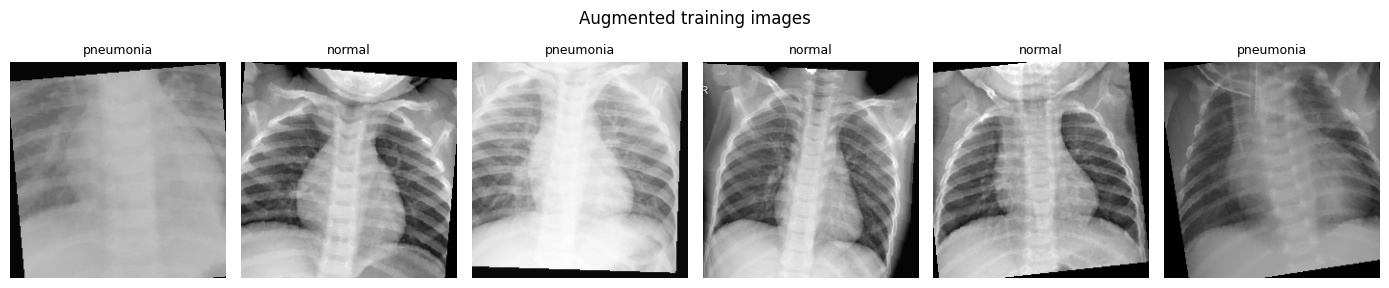

In [5]:
# Look at a few augmented training images
imgs, labels = next(iter(train_loader))
mean = torch.tensor(IMAGENET_MEAN).view(3, 1, 1); std = torch.tensor(IMAGENET_STD).view(3, 1, 1)
fig, axes = plt.subplots(1, 6, figsize=(14, 3))
for ax, img, lab in zip(axes, imgs[:6], labels[:6]):
    ax.imshow((img * std + mean).permute(1, 2, 0).clamp(0, 1))
    ax.set_title("pneumonia" if lab.item() == 1 else "normal", fontsize=9); ax.axis("off")
plt.suptitle("Augmented training images"); plt.tight_layout()
plt.savefig(f"{FIG_DIR}/augmented_examples.png", dpi=150); plt.show()

## 3. The model: transfer learning with ResNet18

- **ResNet18** pre-trained on ImageNet (1.2 million photos): it already knows how to detect edges, textures and shapes.
- We replace the last layer with: **Dropout(0.3) → Linear(512 → 1)**. The output is one number (logit) → probability of pneumonia.
- The **Dropout** layer is important: we will reuse it in notebook 03 to estimate uncertainty (Monte Carlo Dropout).

In [6]:
def build_model(pretrained=True, dropout=0.3):
    weights = models.ResNet18_Weights.IMAGENET1K_V1 if pretrained else None
    model = models.resnet18(weights=weights)
    model.fc = nn.Sequential(nn.Dropout(p=dropout), nn.Linear(model.fc.in_features, 1))
    return model

model = build_model().to(DEVICE)
n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Trainable parameters: {n_params:,}")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 167MB/s]


Trainable parameters: 11,177,025


## 4. Loss function with class weighting

`pos_weight = n_normal / n_pneumonia` (≈ 0.35). Errors on pneumonia images count less, so that the model does not simply learn to say "pneumonia" because it is the majority class.

In [7]:
y_train = train_ds.labels.ravel()
n_neg, n_pos = int((y_train == 0).sum()), int((y_train == 1).sum())
pos_weight = torch.tensor([n_neg / n_pos], device=DEVICE)
print(f"normal={n_neg}  pneumonia={n_pos}  pos_weight={pos_weight.item():.3f}")

criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-4, weight_decay=1e-4)

normal=1214  pneumonia=3494  pos_weight=0.347


## 5. Training

At each epoch we evaluate on the **validation** set and keep the model with the best **AUC** (area under the ROC curve: 1.0 = perfect, 0.5 = random).

In [8]:
def run_epoch(model, loader, train=True):
    model.train() if train else model.eval()
    total_loss, all_probs, all_labels = 0.0, [], []
    with torch.set_grad_enabled(train):
        for x, y in loader:
            x, y = x.to(DEVICE), y.float().to(DEVICE)
            logits = model(x)
            loss = criterion(logits, y)
            if train:
                optimizer.zero_grad(); loss.backward(); optimizer.step()
            total_loss += loss.item() * x.size(0)
            all_probs.append(torch.sigmoid(logits).detach().cpu())
            all_labels.append(y.cpu())
    probs = torch.cat(all_probs).numpy().ravel()
    labels = torch.cat(all_labels).numpy().ravel()
    return total_loss / len(loader.dataset), roc_auc_score(labels, probs)

In [9]:
EPOCHS = 10
history = {"train_loss": [], "val_loss": [], "train_auc": [], "val_auc": []}
best_auc, best_state = 0.0, None

for epoch in range(1, EPOCHS + 1):
    t0 = time.time()
    tr_loss, tr_auc = run_epoch(model, train_loader, train=True)
    va_loss, va_auc = run_epoch(model, val_loader, train=False)
    for k, v in zip(history, [tr_loss, va_loss, tr_auc, va_auc]):
        history[k].append(v)
    flag = ""
    if va_auc > best_auc:
        best_auc, best_state = va_auc, copy.deepcopy(model.state_dict())
        torch.save(best_state, MODEL_PATH); flag = "  ← best, saved"
    print(f"Epoch {epoch:2d}/{EPOCHS} | train loss {tr_loss:.4f} AUC {tr_auc:.4f} | "
          f"val loss {va_loss:.4f} AUC {va_auc:.4f} | {time.time() - t0:.0f}s{flag}")

print(f"\nBest validation AUC: {best_auc:.4f}")

Epoch  1/10 | train loss 0.0788 AUC 0.9861 | val loss 0.0668 AUC 0.9957 | 22s  ← best, saved
Epoch  2/10 | train loss 0.0386 AUC 0.9963 | val loss 0.0408 AUC 0.9966 | 20s  ← best, saved
Epoch  3/10 | train loss 0.0312 AUC 0.9975 | val loss 0.0598 AUC 0.9976 | 20s  ← best, saved
Epoch  4/10 | train loss 0.0206 AUC 0.9988 | val loss 0.0306 AUC 0.9985 | 20s  ← best, saved
Epoch  5/10 | train loss 0.0207 AUC 0.9987 | val loss 0.0214 AUC 0.9989 | 21s  ← best, saved
Epoch  6/10 | train loss 0.0310 AUC 0.9974 | val loss 0.0278 AUC 0.9983 | 20s
Epoch  7/10 | train loss 0.0184 AUC 0.9992 | val loss 0.0309 AUC 0.9983 | 21s
Epoch  8/10 | train loss 0.0123 AUC 0.9995 | val loss 0.0450 AUC 0.9991 | 20s  ← best, saved
Epoch  9/10 | train loss 0.0197 AUC 0.9986 | val loss 0.0286 AUC 0.9988 | 20s
Epoch 10/10 | train loss 0.0117 AUC 0.9996 | val loss 0.0326 AUC 0.9981 | 21s

Best validation AUC: 0.9991


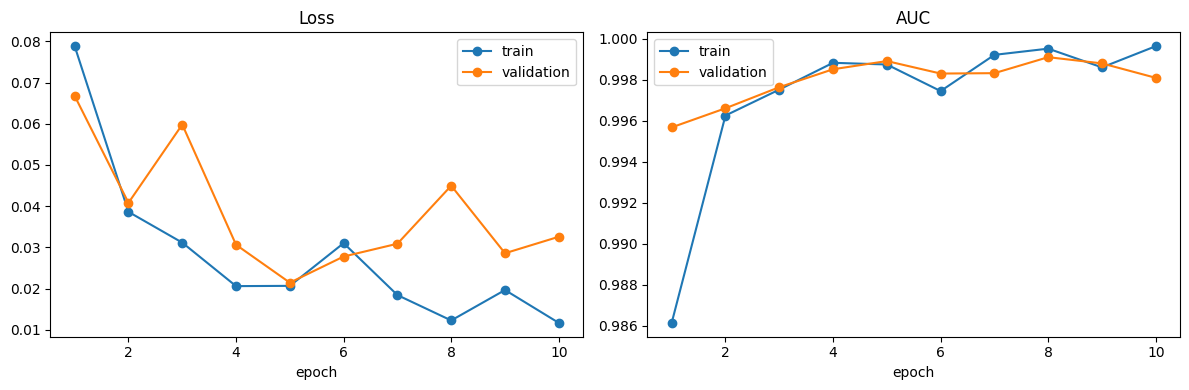

In [10]:
ep = range(1, len(history["train_loss"]) + 1)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(ep, history["train_loss"], "o-", label="train"); ax1.plot(ep, history["val_loss"], "o-", label="validation")
ax1.set_title("Loss"); ax1.set_xlabel("epoch"); ax1.legend()
ax2.plot(ep, history["train_auc"], "o-", label="train"); ax2.plot(ep, history["val_auc"], "o-", label="validation")
ax2.set_title("AUC"); ax2.set_xlabel("epoch"); ax2.legend()
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/training_curves.png", dpi=150); plt.show()

## 6. Choose the decision threshold on the validation set

By default a model says "pneumonia" if probability > 0.5. Because of the class imbalance and the distribution shift, 0.5 is not necessarily the best choice.

We choose the threshold that maximizes **Youden's J = sensitivity + specificity − 1** on the **validation set only**. The test set stays untouched, like a final exam we never look at before.

In [11]:
model.load_state_dict(torch.load(MODEL_PATH, map_location=DEVICE))
model.eval()

@torch.no_grad()
def predict(model, loader):
    probs, labels = [], []
    for x, y in loader:
        probs.append(torch.sigmoid(model(x.to(DEVICE))).cpu())
        labels.append(y)
    return torch.cat(probs).numpy().ravel(), torch.cat(labels).numpy().ravel()

val_probs, val_labels = predict(model, val_loader)
fpr, tpr, thr = roc_curve(val_labels, val_probs)
best_idx = np.argmax(tpr - fpr)
THRESHOLD = float(thr[best_idx])
print(f"Chosen threshold (Youden, validation): {THRESHOLD:.3f}")
print(f"  validation sensitivity = {tpr[best_idx]:.3f}, specificity = {1 - fpr[best_idx]:.3f}")

Chosen threshold (Youden, validation): 0.043
  validation sensitivity = 0.992, specificity = 0.993


## 7. Final evaluation on the test set (never seen before)

In [12]:
test_probs, test_labels = predict(model, test_loader)

def report(labels, probs, threshold, name):
    preds = (probs >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(labels, preds, labels=[0, 1]).ravel()
    m = {
        "threshold": threshold,
        "accuracy": (tp + tn) / len(labels),
        "sensitivity (recall)": tp / (tp + fn),
        "specificity": tn / (tn + fp),
        "precision (PPV)": tp / (tp + fp) if tp + fp else 0.0,
        "NPV": tn / (tn + fn) if tn + fn else 0.0,
        "AUC": roc_auc_score(labels, probs),
    }
    print(f"--- {name} ---")
    for k, v in m.items():
        print(f"{k:22s}: {v:.3f}")
    print(f"TN={tn}  FP={fp}  FN={fn}  TP={tp}\n")
    return m, (tn, fp, fn, tp)

m05, cm05 = report(test_labels, test_probs, 0.5, "Test @ threshold 0.5")
mth, cmth = report(test_labels, test_probs, THRESHOLD, f"Test @ threshold {THRESHOLD:.3f} (chosen on validation)")
print(f"Baseline 'always pneumonia' accuracy: {(test_labels == 1).mean():.3f}")

--- Test @ threshold 0.5 ---
threshold             : 0.500
accuracy              : 0.963
sensitivity (recall)  : 0.982
specificity           : 0.932
precision (PPV)       : 0.960
NPV                   : 0.969
AUC                   : 0.990
TN=218  FP=16  FN=7  TP=383

--- Test @ threshold 0.043 (chosen on validation) ---
threshold             : 0.043
accuracy              : 0.949
sensitivity (recall)  : 0.992
specificity           : 0.876
precision (PPV)       : 0.930
NPV                   : 0.986
AUC                   : 0.990
TN=205  FP=29  FN=3  TP=387

Baseline 'always pneumonia' accuracy: 0.625


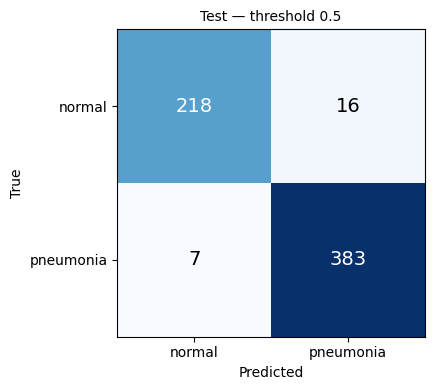

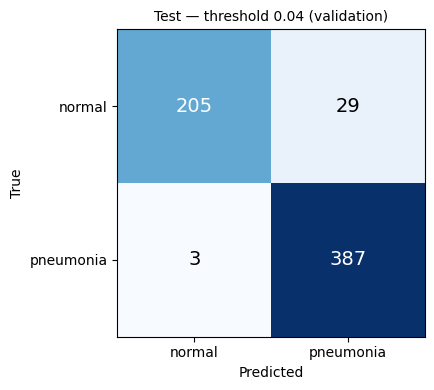

In [13]:
def plot_cm(cm, title, path):
    tn, fp, fn, tp = cm
    mat = np.array([[tn, fp], [fn, tp]])
    fig, ax = plt.subplots(figsize=(4.5, 4))
    ax.imshow(mat, cmap="Blues")
    for i in range(2):
        for j in range(2):
            ax.text(j, i, mat[i, j], ha="center", va="center", fontsize=14,
                    color="white" if mat[i, j] > mat.max() / 2 else "black")
    ax.set_xticks([0, 1]); ax.set_xticklabels(["normal", "pneumonia"])
    ax.set_yticks([0, 1]); ax.set_yticklabels(["normal", "pneumonia"])
    ax.set_xlabel("Predicted"); ax.set_ylabel("True"); ax.set_title(title, fontsize=10)
    plt.tight_layout(); plt.savefig(path, dpi=150); plt.show()

plot_cm(cm05, "Test — threshold 0.5", f"{FIG_DIR}/cm_test_05.png")
plot_cm(cmth, f"Test — threshold {THRESHOLD:.2f} (validation)", f"{FIG_DIR}/cm_test_tuned.png")

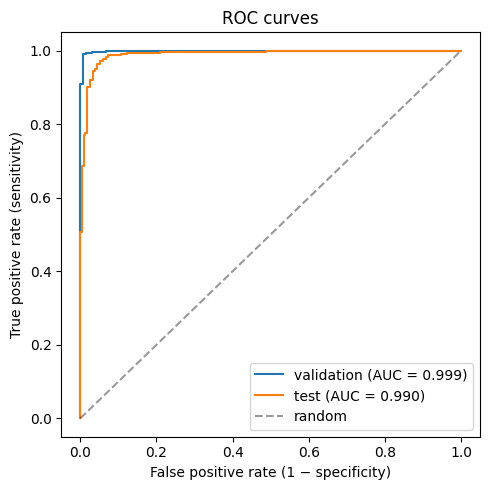

In [14]:
plt.figure(figsize=(5, 5))
for labels, probs, name in [(val_labels, val_probs, "validation"), (test_labels, test_probs, "test")]:
    f, t, _ = roc_curve(labels, probs)
    plt.plot(f, t, label=f"{name} (AUC = {roc_auc_score(labels, probs):.3f})")
plt.plot([0, 1], [0, 1], "k--", alpha=0.4, label="random")
plt.xlabel("False positive rate (1 − specificity)"); plt.ylabel("True positive rate (sensitivity)")
plt.title("ROC curves"); plt.legend(); plt.tight_layout()
plt.savefig(f"{FIG_DIR}/roc_curves.png", dpi=150); plt.show()



## 8. Observations

- **Best validation AUC:** 0.9991 (epoch 8). Slight overfitting after epoch 5 (validation loss oscillates while training loss keeps decreasing) — controlled by keeping the best model on validation AUC.
- **Test results:** AUC 0.990. At threshold 0.5: sensitivity 98.2%, specificity 93.2% (7 FN, 16 FP). At the threshold tuned on validation (0.043): sensitivity 99.2%, specificity 87.6% (3 FN, 29 FP).
- **Clinical trade-off:** the tuned threshold halves missed pneumonia cases (7 → 3) at the cost of more false alarms (16 → 29). For a screening tool, sensitivity is prioritized: choosing the operating point is a clinical decision.
- **Distribution shift confirmed:** validation (AUC 0.999, specificity 99.3%) is much more optimistic than test (AUC 0.990, specificity 87.6%), as predicted in notebook 01.
- **Very low threshold (0.043):** class weighting shifts probabilities downward → predicted probabilities are not calibrated. The near-perfect validation set (only 135 normal cases) also makes the threshold unstable.
- **Next step:** high scores do not tell us whether the model is *sure* of each prediction, nor whether it looks at the lungs → notebook 03 (Monte Carlo Dropout uncertainty) and Grad-CAM.